# Setup

In [1]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery
library(data.table )

# Load required libraries
library(dplyr)
library(tidyr)
library(purrr)
library(broom)

install.packages("metafor")
library(metafor)

install.packages("pROC")
library(pROC)

## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}

disease_name_mapping <- c(
  "Asthma" = "Asthma",
    "BreastC" = "Breast\nCancer",
    "CKD" = "CKD", 
    "CHD" = "CHD",
    "ProstateC" = "Prostate\nCancer", 
  "t2d" = "T2D",
  "t1d" = "T1D"
)


[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Loading required package: viridisLite


Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal



Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr   1.2.1     ✔ readr   2.2.0
✔ forcats 1.0.1     ✔ stringr 1.6.0
✔ ggplot2 4.0.2     ✔ tibble  3.3.1
✔ purrr   1.2.1     ✔ tidyr   1.3.2
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ readr::col_factor() masks scales::col_factor()
✖ purrr::discard()    masks scales::discard()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘data.table’


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is

## Load and merge data

In [2]:
diseases<-c("Asthma", "BreastC", "CKD", "CHD", "ProstateC", "t2d")

#Load MGBB betas
MGBB_weights <- read.csv("/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data/joint_model_coeff_results_MGBB.csv")
MGBB_weights <- MGBB_weights |>
  mutate(Training = if_else(
    grepl("MGBB", Model),
    "MGBB",
    "AoU"
  ))
MGBB_weights$Testing <- "MGBB"

#Align disease names from MGBB
MGBB_weights$Disease <- factor(
  MGBB_weights$Disease,
  levels = c("asthma", "bc", "ckd", "chd", "pc", "t2d"),
  labels = c("Asthma", "BreastC", "CKD", "CHD", "ProstateC", "t2d")
)


#Load PEGS betas
PEGS_weights <- read.csv("/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data/joint_model_coeff_results_PEGS.csv")
PEGS_weights$Training <- "AoU"
PEGS_weights$Testing <- "PEGS"

#Load PEGS internally trained PsRS betas
PEGS_weights_int <- read.csv("/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data/joint_model_coeff_results_PEGS_internal_training.csv")
PEGS_weights_int$Training <- "PEGS"
PEGS_weights_int$Testing <- "PEGS"

#Merge cohort data
cohort_data<-rbind(MGBB_weights, PEGS_weights)

#Load AoU betas
AoU_weights <- read.csv("/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data/joint_model_coeff_results.csv")
AoU_weights$Training <- "AoU"
AoU_weights$Testing <- "AoU"

cohort_data_plus <- rbind(cohort_data, PEGS_weights_int)
cohort_data_plus_AoU <- rbind(cohort_data_plus, AoU_weights)

In [3]:
cohort_data_social <- cohort_data_plus |>
  filter(str_detect(Model, "Social")) |>
  filter(Disease %in% diseases) |>
  filter(grepl("AoU", Training))

cohort_data_social$Model <- "Social"

cohort_data_plus_AoU_social<- cohort_data_plus_AoU |>
  filter(str_detect(Model, "Social")) |>
  filter(Disease %in% diseases)

cohort_data_plus_AoU_social$Model <- "Social"

cohort_data_plus_AoU_social

Model,Disease,term,estimate,std.error,statistic,p.value,Training,Testing
<chr>,<fct>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
Social,t2d,mgbb_t2d_PsRS,0.30055348,0.022330366,13.45940701,2.710000e-41,MGBB,MGBB
Social,t2d,aou_t2d_PsRS,0.30466688,0.021086967,14.44811260,2.580000e-47,AoU,MGBB
Social,BreastC,mgbb_bc_PsRS,0.08653898,0.030600752,2.82800159,4.683957e-03,MGBB,MGBB
Social,BreastC,aou_bc_PsRS,0.12177916,0.026536731,4.58907934,4.450000e-06,AoU,MGBB
Social,ProstateC,mgbb_pc_PsRS,0.11831063,0.035888058,3.29665740,9.780000e-04,MGBB,MGBB
Social,ProstateC,aou_pc_PsRS,0.08241184,0.036138102,2.28046963,2.257985e-02,AoU,MGBB
Social,Asthma,mgbb_asthma_PsRS,0.03833683,0.024964116,1.53567730,1.246175e-01,MGBB,MGBB
Social,Asthma,aou_asthma_PsRS,0.01734673,0.027307977,0.63522571,5.252812e-01,AoU,MGBB
Social,CHD,mgbb_chd_PsRS,0.27239015,0.027426992,9.93146265,3.040000e-23,MGBB,MGBB


# Meta-analysis

In [4]:
# initialize empty data frame
results_df_fe <- data.frame()
results_df_reml <- data.frame()

for (disease in diseases) {
    print(disease)
     cohort_data_subset <- cohort_data_social[cohort_data_social$Disease == disease, ]

    fixed_effect <-metafor::rma(yi = cohort_data_subset$estimate, 
                                sei = cohort_data_subset$std.error, 
                                method = "FE")
    
    random_effect <-metafor::rma(yi = cohort_data_subset$estimate, 
                                 sei = cohort_data_subset$std.error, 
                                 method = "REML")

      #formatting
      vals <- signif(cohort_data_subset$p.value, 2)  # 2 significant figures
      vals_sci <- formatC(vals, format = "e", digits = 1) # scientific notation

     res_temp_fe <- data.frame(
        #Meta data
        Disease = disease, 
        Training = "AoU",
        Testing = "FE meta-analysis (MGBB & PEGS)",
        #Fixed effect meta-analysis stats
        estimate = fixed_effect$beta,
        std.error = fixed_effect$se,
        p.value = fixed_effect$pval,
        Q = fixed_effect$QE, 
        Q.p.value = fixed_effect$QEp,
        I2 = fixed_effect$I2)   

    res_temp_reml <- data.frame(
        #Meta data
        Disease = disease, 
        Training = "AoU",
        Testing = "RE meta-analysis (MGBB & PEGS)",
        #Fixed effect meta-analysis stats
        estimate = random_effect$beta,
        std.error = random_effect$se,
        p.value = random_effect$pval,
        Q = random_effect$QE, 
        Q.p.value = random_effect$QEp,
        I2 = random_effect$I2)  

    results_df_fe <- bind_rows(results_df_fe, res_temp_fe)
    results_df_reml <- bind_rows(results_df_reml, res_temp_reml)
    
} 
    


[1] "Asthma"
[1] "BreastC"
[1] "CKD"
[1] "CHD"
[1] "ProstateC"
[1] "t2d"


## Add back to original results

In [5]:
cohort_data_plus_AoU_social <- cohort_data_plus_AoU_social |> select(Disease, Training, Testing, estimate, std.error, p.value)
results_df_fe <- results_df_fe |> select(Disease, Training, Testing, estimate, std.error, p.value)
results_df_reml <- results_df_reml |> select(Disease, Training, Testing, estimate, std.error, p.value)
meta_results <- rbind(results_df_fe, results_df_reml)
all_results <- rbind(cohort_data_plus_AoU_social, meta_results)
#all_results$Disease <- disease_name_mapping[all_results$Disease]

#Convert to OR
all_results <- all_results |>
    mutate(OR = exp(estimate),
          OR_Lower = exp(estimate - 1.96 * std.error),
          OR_Upper = exp(estimate + 1.96 * std.error))

write.csv(all_results, "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data/external_testing_OR_results.csv", row.names = FALSE)

# Plot

In [6]:
all_results_no_internal <- all_results |>
  filter(grepl("AoU", Training)) 

all_results_no_internal$sig <- ifelse(all_results_no_internal$p.value < 0.05/nrow(all_results), "True", "False")
nrow(all_results_no_internal)
0.05/nrow(all_results_no_internal)

all_results_no_internal$Disease <- disease_name_mapping[all_results_no_internal$Disease]
all_results_no_internal$Disease <- factor(all_results_no_internal$Disease, levels = rev(c("Breast\nCancer", 
                                                                    "Prostate\nCancer",
                                                                  "T2D", "CKD", "CHD", "Asthma")))

all_results_no_internal$Testing <- factor(all_results_no_internal$Testing, levels = rev(c("AoU", "MGBB", "PEGS",
                                                                  "FE meta-analysis (MGBB & PEGS)",
                                                                    'RE meta-analysis (MGBB & PEGS)')))

[1] 30

[1] 0.001666667

In [7]:
unique(all_results_no_internal$Testing)

[1] MGBB                           PEGS                          
[3] AoU                            FE meta-analysis (MGBB & PEGS)
[5] RE meta-analysis (MGBB & PEGS)
5 Levels: RE meta-analysis (MGBB & PEGS) ... AoU

Warning message:
“`geom_errorbarh()` was deprecated in ggplot2 4.0.0.
ℹ Please use the `orientation` argument of `geom_errorbar()` instead.”
Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the ggplot2 package.
  Please report the issue at <https://github.com/tidyverse/ggplot2/issues>.”
`height` was translated to `width`.
`height` was translated to `width`.


AoU                           MGBB 
                     "#E69F00"                      "#0072B2" 
                          PEGS FE meta-analysis (MGBB & PEGS) 
                     "#D55E00"                      "#009E73" 
RE meta-analysis (MGBB & PEGS) 
                     "#CC79A7"

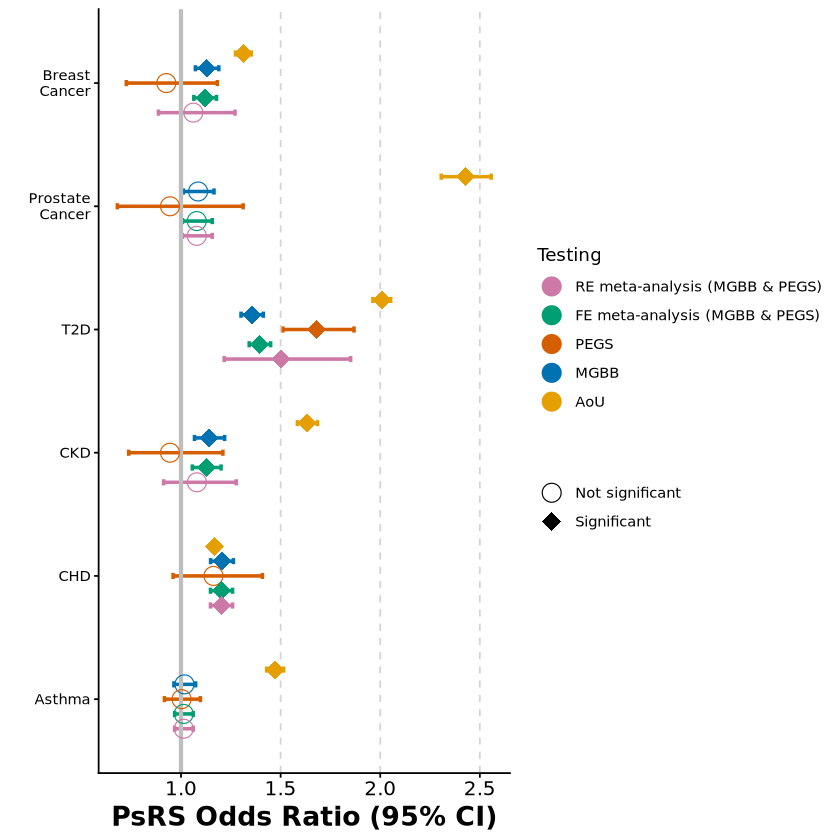

In [8]:
cohort_colors <- c(
  "AoU" = "#E69F00",                          # orange
  "MGBB" = "#0072B2",                         # blue
  "PEGS" = "#D55E00",                         # vermillion
  "FE meta-analysis (MGBB & PEGS)" = "#009E73", # bluish green
  "RE meta-analysis (MGBB & PEGS)" = "#CC79A7"  # reddish purple
)

pd <- position_dodge(width = 0.6)


plot<- ggplot(all_results_no_internal,
    aes(x = OR, y = Disease, color = Testing, shape = sig)
  ) +   
    geom_errorbarh(
      aes(
        xmin = OR_Lower,
        xmax =  OR_Upper),
      height = 0.25,
        position = pd,
        size = 1,
      show.legend = FALSE
    ) +
      scale_shape_manual(
        values = c(`False` = 1, `True` = 18),
        labels = c("Not significant", "Significant"),
        name = ""
      ) +
     scale_color_manual(values = cohort_colors) +
    # Reference lines
    geom_vline(xintercept = 1, color = "grey", linewidth = 1.2) +
    geom_vline(xintercept = 1.5, linetype = "dashed", color = "lightgrey", linewidth = .5) +
    geom_vline(xintercept = 2, linetype = "dashed", color = "lightgrey", linewidth = .5) +
    geom_vline(xintercept = 2.5, linetype = "dashed", color = "lightgrey", linewidth = .5) +

    # Points
    geom_point(
        position = pd,
        size = 5)   +

    labs(
      y     = "",
      x = "PsRS Odds Ratio (95% CI)"
    ) + theme_classic() +
    theme(
    axis.title.x = element_text(size=16, face = "bold"),
                               axis.text.x = element_text(size=12)
        ) 
plot
ggplot_build(plot)$plot$scales$get_scales("colour")$palette(
  length(unique(all_results_no_internal$Testing))
)
    

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_text()`).”


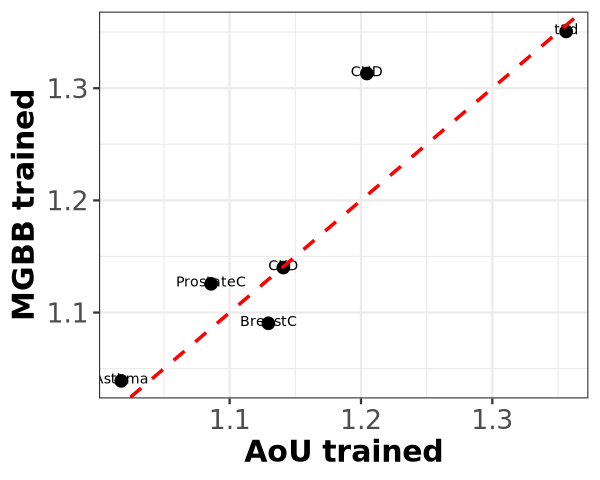

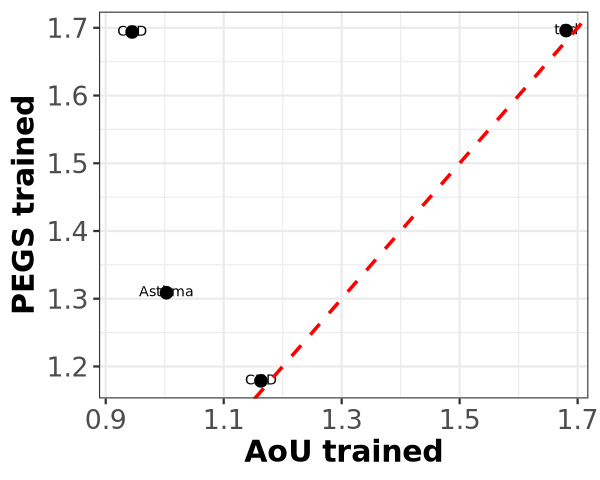

In [9]:
options(repr.plot.width = 5, repr.plot.height = 4)

compare_training_OR <- function(df, cohort) {
     df_subset <- df |> 
        filter(grepl(cohort, Testing),
          !grepl("meta", Testing))


    df_long <- df_subset  |>
         pivot_wider(
            id_cols = c(Disease, Testing),
            names_from = Training,
            values_from = OR,
            names_prefix = "OR_"
          )
    y_axis <- paste0("OR_", cohort)
    plot <- ggplot(data = df_long, aes(x = OR_AoU, y = .data[[y_axis]])) +
          geom_point(size=3) + 
          geom_text(aes(label = Disease), nudge_y = 0.002, size = 3) +
          geom_abline(intercept = 0, slope = 1, color = "red", linetype = "dashed", linewidth = 1)  +
        theme(
          axis.title.x = element_text(size = 18, face = "bold"),
          axis.title.y = element_text(size = 18),
          axis.text.x = element_text(size = 16),
          axis.text.y = element_text(size = 16),
          title = element_text(size = 18, face = "bold")
        )

    return(plot)

    }

compare_training_OR(all_results, "MGBB") +
    labs(
         x = "AoU trained",
        y = "MGBB trained"
        )


compare_training_OR(all_results, "PEGS") +
    labs(
         x = "AoU trained",
        y = "PEGS trained"
        )

# Load and merge data for AUC

In [10]:
MGBB_AUC <- read.csv("/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data/aou_auc_joint_model_plot_data_MGBB.csv")
MGBB_AUC_MGBB_train <- read.csv("/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data/mgbb_auc_joint_model_plot_data.csv")

PEGS_AUC <- read.csv("/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data/auc_joint_model_plot_data_PEGS.csv")
PEGS_AUC_PEGS_train <- read.csv("/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data/auc_joint_model_plot_data_PEGS_internal_training.csv")

PEGS_AUC$Training <- "AoU"
PEGS_AUC_PEGS_train$Training <- "Internal"
PEGS_AUC_merged <- rbind(PEGS_AUC, PEGS_AUC_PEGS_train)
PEGS_AUC_merged$Testing <- "PEGS"
MGBB_AUC$Training <- "AoU"
MGBB_AUC_MGBB_train$Training <- "Internal"
MGBB_AUC_merged <- rbind(MGBB_AUC, MGBB_AUC_MGBB_train)
MGBB_AUC_merged$Testing <- "MGBB"
MGBB_AUC_merged <- MGBB_AUC_merged |>
  mutate(Model = str_remove(Model, "^AOU_"),
        Model = str_remove(Model, "^MGBB_"))

all_AUC_data <- rbind(MGBB_AUC_merged, PEGS_AUC_merged)
write.csv(all_AUC_data, "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data/all_external_AUC.csv", row.names = FALSE)

## Function for comparing internal vs AoU trained PsRS models

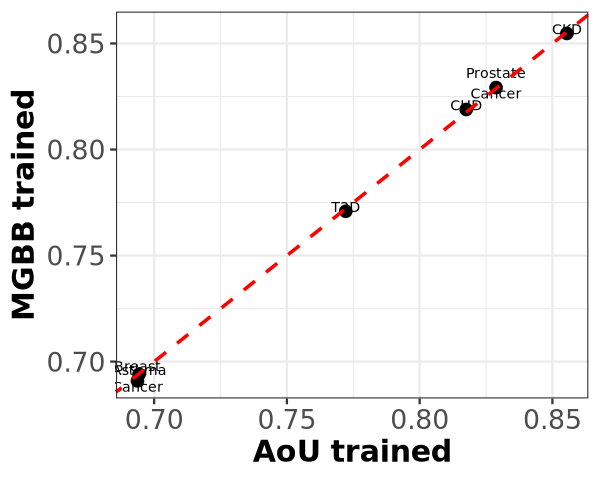

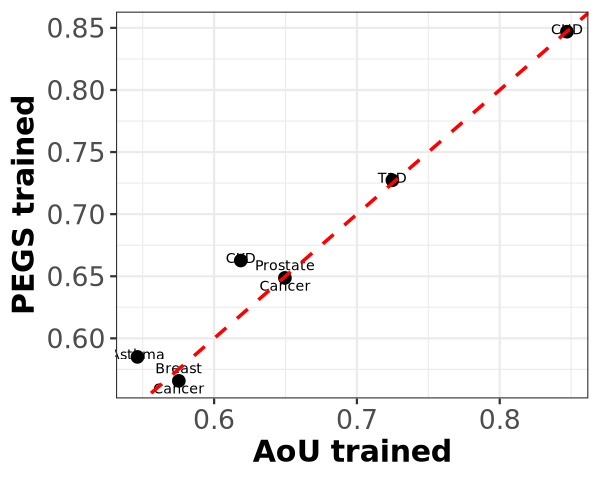

In [11]:
options(repr.plot.width = 5, repr.plot.height = 4)

compare_training <- function(df_AoU, df_int_train) {
    compare_training_df <- rbind(df_AoU, df_int_train)
    compare_training_df_PsRS <- compare_training_df |>
          filter(grepl("Social", Model)) 
    compare_training_df_PsRS$Model <- "Social"
    
    compare_training_df_long <- compare_training_df_PsRS  |>
         pivot_wider(
            id_cols = c(Disease, Model),
            names_from = Training,
            values_from = AUC,
            names_prefix = "AUC_"
          )
    
    plot <- ggplot(data = compare_training_df_long, aes(x = AUC_AoU, y = AUC_Internal)) +
          geom_point(size=3) + 
          geom_text(aes(label = Disease), nudge_y = 0.002, size = 3) +
          geom_abline(intercept = 0, slope = 1, color = "red", linetype = "dashed", linewidth = 1)  +
        theme(
          axis.title.x = element_text(size = 18, face = "bold"),
          axis.title.y = element_text(size = 18),
          axis.text.x = element_text(size = 16),
          axis.text.y = element_text(size = 16),
          title = element_text(size = 18, face = "bold")
        )

    return(plot)

    }

compare_training(MGBB_AUC, MGBB_AUC_MGBB_train) +
    labs(
         x = "AoU trained",
        y = "MGBB trained"
        )

compare_training(PEGS_AUC, PEGS_AUC_PEGS_train) +
    labs(
         x = "AoU trained",
        y = "PEGS trained"
        )

# AUC Plots

In [12]:
MGBB_AUC_comparisons <- read.csv("/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data/auc_comparisons_sdoh_joint_modeling_MGBB.csv")
PEGS_AUC_comparisons <- read.csv("/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data/auc_comparisons_sdoh_joint_modeling_PEGS.csv")
MGBB_AUC_comparisons$Cohort <- "MGBB"
MGBB_AUC_comparisons <- MGBB_AUC_comparisons |>
  filter(
    !grepl("MGBB", Model1),
    !grepl("MGBB", Model2)
  ) |>
  mutate(
    Model1 = str_remove(Model1, "^AOU_"),
    Model2 = str_remove(Model2, "^AOU_")
  )
PEGS_AUC_comparisons$Cohort <- "PEGS"

auc_comparisons <- rbind(MGBB_AUC_comparisons, PEGS_AUC_comparisons)

MGBB_AUC$Model <- str_remove(MGBB_AUC$Model, "^AOU_")

## Prepare to plot

In [13]:
facet_order <- c(
  "Breast\nCancer", "Prostate\nCancer", "T2D",
  "CKD", "CHD", "Asthma"
)



MGBB_AUC_for_plot <- MGBB_AUC %>%
  filter(Model %in% c("Base", "Genetic", "Joint")) |> 
  mutate(
    Model = factor(Model, rev(c("Base", "Genetic", "Joint"))),
    Disease = factor(Disease, facet_order)
  ) 


PEGS_AUC_for_plot <- PEGS_AUC %>%
  filter(Model %in% c("Base", "Genetic", "Joint")) |> 
  mutate(
    Model = factor(Model, rev(c("Base", "Genetic", "Joint"))),
    Disease = factor(Disease, facet_order)
  )

MGBB_AUC_for_plot$Cohort <- "MGBB"
PEGS_AUC_for_plot$Cohort <- "PEGS"

AUC_plot_data_for_plot <- rbind(MGBB_AUC_for_plot, PEGS_AUC_for_plot)

In [14]:
pd <- position_dodge(width = 1)

model_colors <- c(
  "Base"    = "#E69F00", # orange
  "Genetic" = "#0072B2", # blue
  "Joint"   = "#D55E00" # vermillion
)

AUC_plot_data_for_plot$group <-
  interaction(AUC_plot_data_for_plot$Model,
              AUC_plot_data_for_plot$Cohort)


AUC_plot_data_for_plot <- AUC_plot_data_for_plot %>%
  mutate(Disease = factor(Disease, rev(facet_order)))

`height` was translated to `width`.


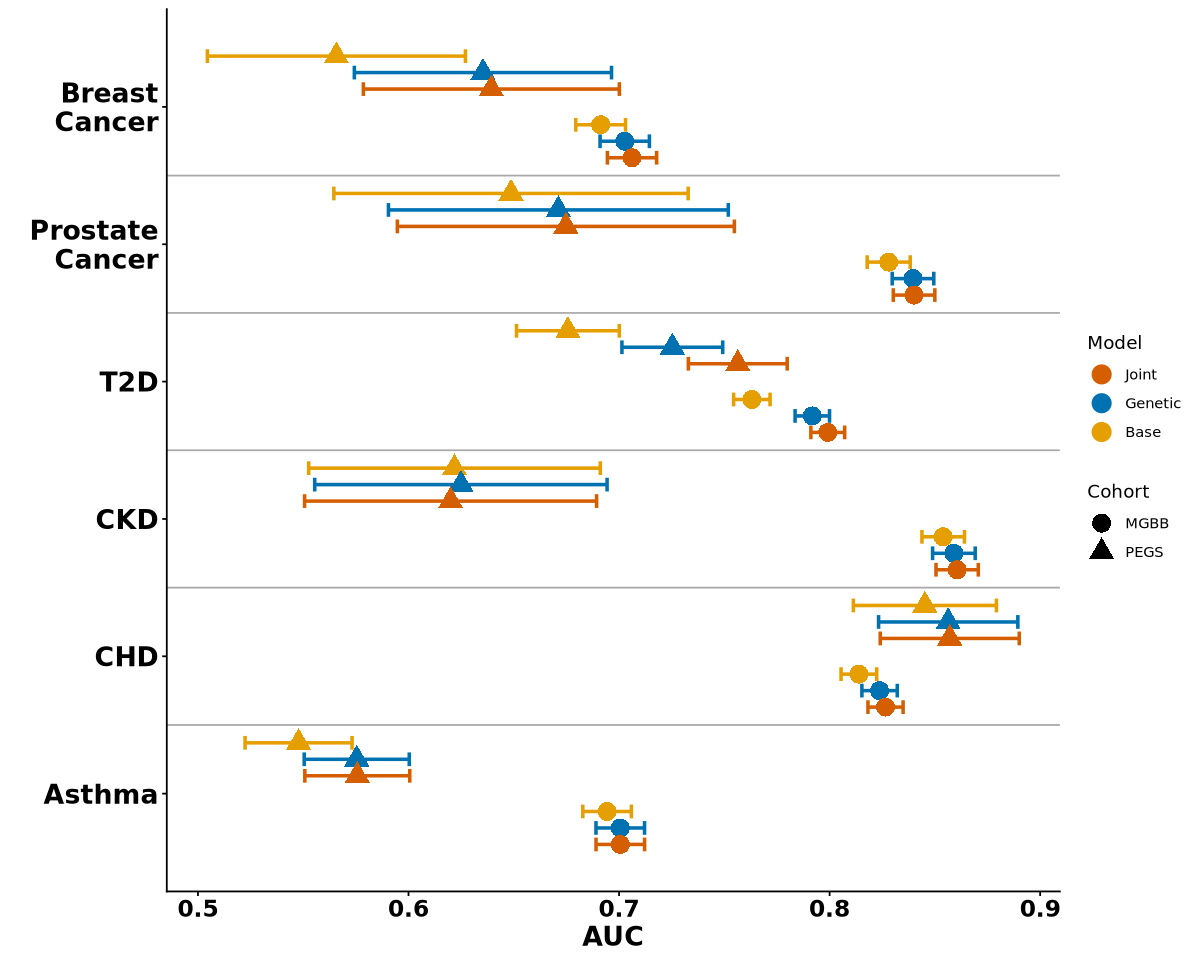

In [15]:
options(repr.plot.width = 10, repr.plot.height = 8)

model_offset <- c(
  Base    = -0.12,
  Genetic =  0.00,
  Joint   =  0.12
)

cohort_offset <- c(
  MGBB  = -0.25,
  PEGS =  0.25
)


AUC_plot_data_for_plot_manual <- AUC_plot_data_for_plot %>%
  mutate(
    y = as.numeric(Disease) + 
        cohort_offset[Cohort] +
        model_offset[Model]
  )

ggplot(AUC_plot_data_for_plot_manual,
       aes(x = AUC, y = y,
           color = Model,
           shape = Cohort)) +
    geom_errorbarh(
      aes(
        xmin = AUC_CI_Lower,
        xmax =  AUC_CI_Upper),
      height = 0.1,
        position = pd,
        size = 1,
      show.legend = FALSE
    ) +
  geom_point(size = 5) +
  scale_color_manual(values = model_colors) +
  scale_y_continuous(
    breaks = seq_along(levels(AUC_plot_data_for_plot$Disease)),
    labels = levels(AUC_plot_data_for_plot$Disease)
  ) +

    labs(
      y     = "",
      x = "AUC"
    ) + theme_classic() +
    theme(
    axis.title.x = element_text(size=16, face = "bold"),
    axis.text.x = element_text(size=14, face = "bold"),
    axis.text.y = element_text(size=16, face = "bold")
        )  +
  geom_hline(yintercept = seq(1.5, length(unique(AUC_plot_data_for_plot_manual$Disease)) - 0.5, 1),
             color = "darkgrey")

In [16]:
gen_joint_lines <- auc_comparisons %>%
  filter(
    (Model1 == "Genetic" & Model2 == "Joint") |
      (Model1 == "Joint" & Model2 == "Genetic")
  ) %>%
  left_join(
    AUC_plot_data_for_plot %>%
      group_by(Disease) %>%
      summarize(
        x = max(AUC_CI_Upper, na.rm = TRUE),
        .groups = "drop"
      ),
    by = "Disease"
  ) %>%
  mutate(
    x = x + 0.03,
    y_start = as.numeric(factor(Disease, levels = levels(AUC_plot_data_for_plot$Disease))) - 0.1,
    y_end   = as.numeric(factor(Disease, levels = levels(AUC_plot_data_for_plot$Disease))) + 0.1
  )

gen_joint_lines

auc_comparisons$Training <- "AoU"
write.csv(auc_comparisons, "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data/all_external_AUC_comparisons.csv", row.names = FALSE)

Disease,Model1,Model2,AUC1,se1,se2,AUC2,p_value,bonf_p,p_value_bonf,significant,level,Cohort,x,y_start,y_end
<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
Asthma,Genetic,Joint,0.6999383,0.000891000,0.000891000,0.6999602,5.539994e-01,0.0002980000,1.000000e+00,FALSE,,MGBB,0.7421203,0.9,1.1
Breast Cancer,Genetic,Joint,0.7028488,0.000903000,0.000901000,0.7066208,9.590000e-16,0.0002980000,1.610000e-13,TRUE,***,MGBB,0.7478527,5.9,6.1
CHD,Genetic,Joint,0.8237390,0.000648000,0.000643000,0.8266116,1.290000e-39,0.0002980000,2.160000e-37,TRUE,***,MGBB,0.9200698,1.9,2.1
CKD,Genetic,Joint,0.8587073,0.000781000,0.000774000,0.8604452,9.670000e-22,0.0002980000,1.620000e-19,TRUE,***,MGBB,0.9006148,2.9,3.1
Prostate Cancer,Genetic,Joint,0.8401773,0.000760000,0.000759000,0.8407598,1.940000e-05,0.0002980000,3.263550e-03,TRUE,**,MGBB,0.8799740,4.9,5.1
T2D,Genetic,Joint,0.7918748,0.000631000,0.000619000,0.7992320,1.010000e-70,0.0002980000,1.690000e-68,TRUE,***,MGBB,0.8371531,3.9,4.1
Asthma,Genetic,Joint,0.5754113,0.006364683,0.006357673,0.5756768,5.263208e-01,0.0008333333,1.000000e+00,FALSE,,PEGS,0.7421203,0.9,1.1
Breast Cancer,Genetic,Joint,0.6353505,0.015579146,0.015508868,0.6393519,4.682337e-01,0.0008333333,1.000000e+00,FALSE,,PEGS,0.7478527,5.9,6.1
CHD,Genetic,Joint,0.8563296,0.008436652,0.008421307,0.8570583,6.104514e-01,0.0008333333,1.000000e+00,FALSE,,PEGS,0.9200698,1.9,2.1
